In [1]:
from pathlib import Path
from factor_analyzer import Rotator, calculate_bartlett_sphericity, calculate_kmo
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler

DATA_PATH = Path("data") / "data.csv"
data = pd.read_csv(DATA_PATH)

cols = [f"k{i}" for i in range(1, 21) if f"k{i}" in data.columns]
data_all = data[cols].copy()

scaler = MinMaxScaler().set_output(transform="pandas")
scaled_data = scaler.fit_transform(data_all)

corr_matrix = data_all.corr(method="spearman")
raw_var = data_all.var()
scaled_var = scaled_data.var()

corr_pairs = []
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        c1, c2 = cols[i], cols[j]
        r_val = corr_matrix.loc[c1, c2]
        if abs(r_val) >= 0.70:
            corr_pairs.append({
                "Var 1": c1,
                "Var 2": c2,
                "r": r_val,
                "Raw σ² (Var_1)": raw_var[c1],
                "Raw σ² (Var_2)": raw_var[c2],
                "Scaled σ² (Var_1)": scaled_var[c1],
                "Scaled σ² (Var_2)": scaled_var[c2]
            })

corr_summary = pd.DataFrame(corr_pairs)
print("Strongly correlated pairs (|r| >= 0.70) and variances:")
display(corr_summary)

cols_to_drop = ["k1", "k5", "k8", "k18", "k20"]
reason = """Dropped k1: k1 ~ k3 and k1 ~ k4, but r(k3, k4) < 0.7;
Dropped k5 and k8: k5 ~ k8 ~ k9, of which argmax of scaled σ² = k8 and but argmax of raw σ² = k9;
Dropped k18 and k20: k18 ~ k19 ~ k20, of which argmax σ² = k19."""
selected_cols = [c for c in cols if c not in cols_to_drop]
data_reduced = data_all[selected_cols].copy()

print(f"Dropped {len(cols_to_drop)} features: {cols_to_drop}:\n\n{reason}")

Strongly correlated pairs (|r| >= 0.70) and variances:


,Var 1,Var 2,r,Raw σ² (Var_1),Raw σ² (Var_2),Scaled σ² (Var_1),Scaled σ² (Var_2)
0,k1,k3,0.789124,1.813972,0.482450,0.009137,0.015457
1,k1,k4,0.760712,1.813972,0.374215,0.009137,0.012385
2,k5,k8,-0.997199,0.038227,0.037341,0.033156,0.042595
3,k5,k9,-0.738865,0.038227,45.230050,0.033156,0.004569
4,k8,k9,0.738586,0.037341,45.230050,0.042595,0.004569
5,k18,k19,0.786417,0.011926,0.008343,0.003577,0.011515
6,k18,k20,0.751414,0.011926,0.016307,0.003577,0.005116
7,k19,k20,0.935116,0.008343,0.016307,0.011515,0.005116


Dropped 5 features: ['k1', 'k5', 'k8', 'k18', 'k20']:

Dropped k1: k1 ~ k3 and k1 ~ k4, but r(k3, k4) < 0.7;
Dropped k5 and k8: k5 ~ k8 ~ k9, of which argmax of scaled σ² = k8 and but argmax of raw σ² = k9;
Dropped k18 and k20: k18 ~ k19 ~ k20, of which argmax σ² = k19.


In [2]:
scaler = StandardScaler()
standard_data = scaler.fit_transform(data_reduced)

chi_square, p_value = calculate_bartlett_sphericity(standard_data)
kmo_per_var, kmo_total = calculate_kmo(standard_data)

criteria = pd.DataFrame({
    'Criteria': [
        'KMO statistic',
        'Bartlett sphericity χ²',
        'Bartlett sphericity p-value'
    ],
    'Value': [
        f"{kmo_total:.4f}",
        f"{chi_square:.4f}",
        f"{p_value:.4f}"
    ]
})

display(criteria)

low_kmo_vars = pd.DataFrame({
    'Variable': data_reduced.columns,
    'KMO': np.round(kmo_per_var, 4)
}).sort_values(by='KMO')

print("\nVariables with KMO < 0.5:")
display(low_kmo_vars[low_kmo_vars['KMO'] < 0.5])


,Criteria,Value
0,KMO statistic,0.6494
1,Bartlett sphericity χ²,13259.7116
2,Bartlett sphericity p-value,0.0000



Variables with KMO < 0.5:


,Variable,KMO
11,k15,0.4086


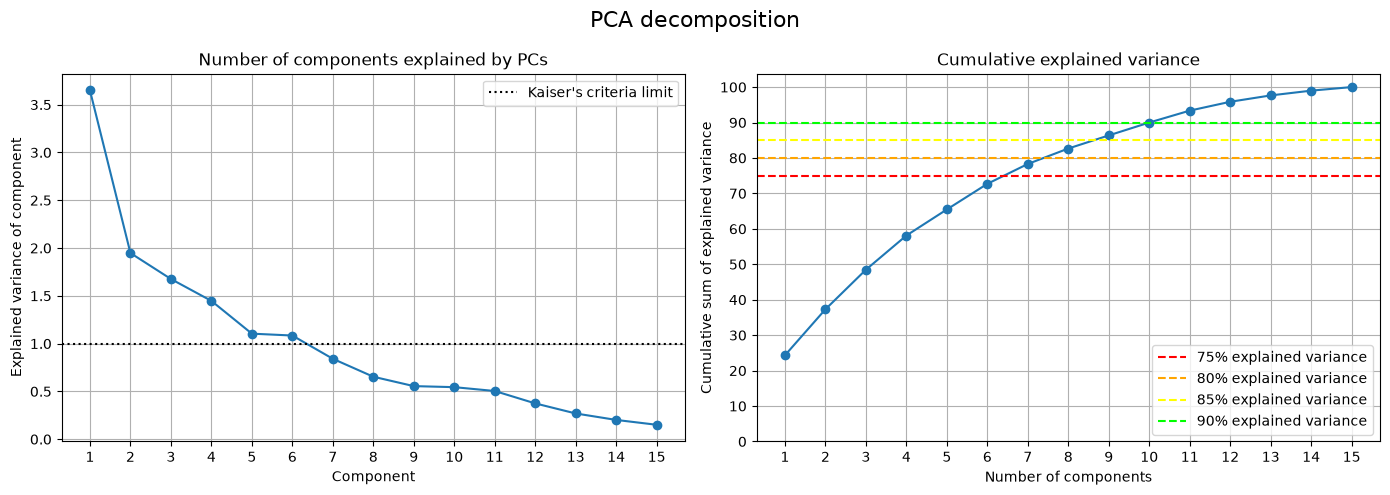

In [3]:
pca = PCA()
data_pca = pca.fit_transform(standard_data)

x = range(1, 16)
y = pca.explained_variance_

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(x, y, marker='o')
plt.axhline(y=1, xmin=0, xmax=1, linestyle=':', color='black', label="Kaiser's criteria limit")
plt.grid(True)
plt.legend()
plt.xticks(x)
plt.xlabel("Component")
plt.ylabel("Explained variance of component")
plt.title("Number of components explained by PCs")

x = range(1, 16)
y = np.cumsum(pca.explained_variance_ratio_) * 100

plt.subplot(1, 2, 2)
plt.plot(x, y, marker='o')
plt.axhline(y=75, linestyle='--', color='red', label="75% explained variance")
plt.axhline(y=80, linestyle='--', color='orange', label="80% explained variance")
plt.axhline(y=85, linestyle='--', color='yellow', label="85% explained variance")
plt.axhline(y=90, linestyle='--', color='lime', label="90% explained variance")
plt.grid(True)
plt.legend(loc="lower right")
plt.xticks(x)
plt.yticks(range(0, 101, 10))
plt.xlabel("Number of components")
plt.ylabel("Cumulative sum of explained variance")
plt.title("Cumulative explained variance")

plt.suptitle("PCA decomposition", fontsize=16)
plt.tight_layout()
plt.show()

,communality_6,communality_7
k2,0.788718,0.827285
k3,0.792684,0.821781
k4,0.522835,0.573833
k6,0.744861,0.789184
k7,0.620054,0.644083
k9,0.800816,0.833128
k10,0.686603,0.687588
k11,0.708286,0.740506
k12,0.745579,0.754168
k13,0.841661,0.856603


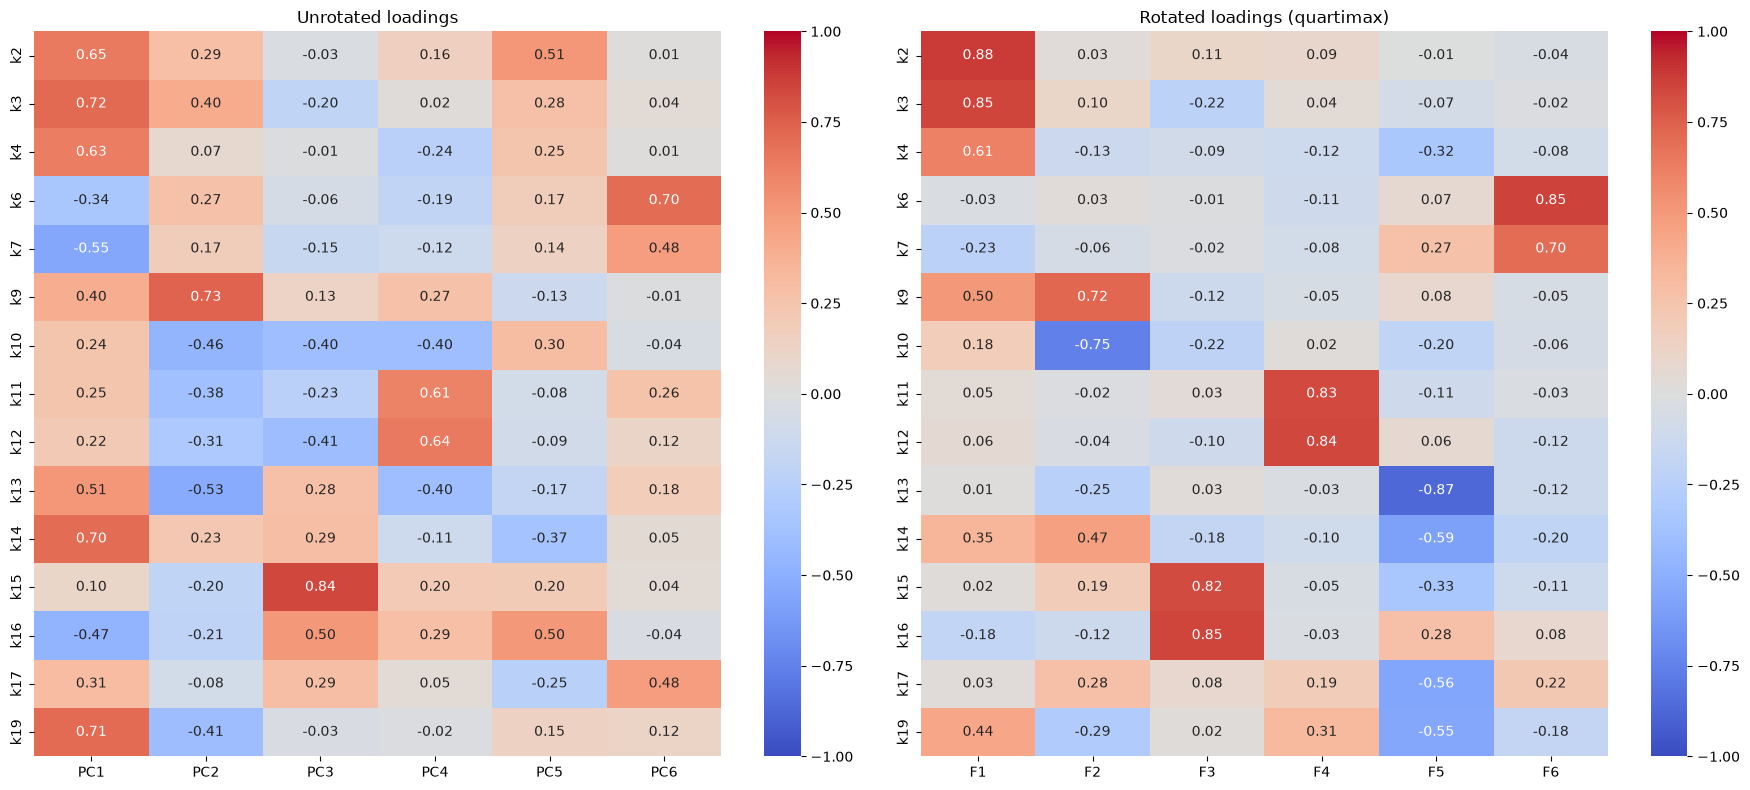

In [4]:
factor_loadings = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_), index = data_reduced.columns, columns=[f'PC{i}' for i in range(1, 16)])

communality_6 = factor_loadings.iloc[:, :6].pow(2).sum(axis=1)
communality_7 = factor_loadings.iloc[:, :7].pow(2).sum(axis=1)
communalities = pd.DataFrame((communality_6, communality_7), index=[f'communality_{i}' for i in [6, 7]]).T
display(communalities)

plt.figure(figsize=(18, 8))

plt.subplot(1, 2, 1)
plt.title("Unrotated loadings")
sns.heatmap(factor_loadings.iloc[:, :6], annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)

plt.subplot(1, 2, 2)
plt.title("Rotated loadings (quartimax)")
rotator_quartimax = Rotator(method='quartimax')
quartimax_loadings = pd.DataFrame(rotator_quartimax.fit_transform(factor_loadings.iloc[:, :6]), index=data_reduced.columns, columns=[f'F{i}' for i in range(1, 7)])
sns.heatmap(quartimax_loadings, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.tight_layout()
plt.show()